1. DATASET
emotion
angry      60
happy      60
neutral    60
sad        60
Split strategy: speaker-independent (10 speakers)
  train     :   144 files,   6 speakers
  validation:    48 files,   2 speakers
  test      :    48 files,   2 speakers

2. FEATURE EXTRACTION
Sequence shape per clip: (130, 116)  (frames x [40 MFCC + 12 Chroma + 64 Mel])
Train: 144 (augment=False)  Val: 48  Test: 48

3. TRAINING (rf)
4. EVALUATION

VALIDATION - classification report
              precision    recall  f1-score   support

       angry      1.000     1.000     1.000        12
       happy      1.000     1.000     1.000        12
     neutral      1.000     1.000     1.000        12
         sad      1.000     1.000     1.000        12

    accuracy                          1.000        48
   macro avg      1.000     1.000     1.000        48
weighted avg      1.000     1.000     1.000        48


TEST - classification report
              precision    recall  f1-score   support

       angry      1

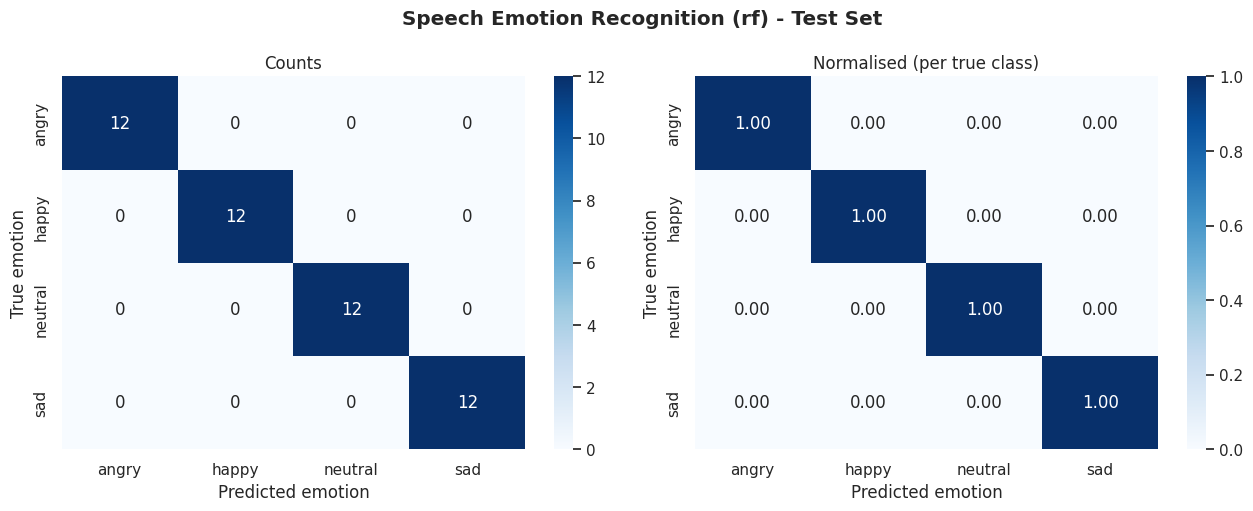

5. INFERENCE DEMO
File: /content/data/demo/angry/spk01_000.wav  (true emotion: angry)
{'emotion': 'angry', 'confidence': 0.995, 'probabilities': {'angry': 0.995, 'happy': 0.005, 'neutral': 0.0, 'sad': 0.0}}

NOTE: the demo dataset is synthetic. These numbers only prove the pipeline runs.


In [6]:


from __future__ import annotations

import argparse
import json
import os
import random
import re
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, List, Optional, Tuple

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import soundfile as sf
from joblib import Parallel, delayed
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_class_weight


SEED = 42
try:
    PROJECT_ROOT = Path(__file__).resolve().parents[1]
except NameError:
    PROJECT_ROOT = Path.cwd()
DATA_DIR = PROJECT_ROOT / "data"
MODELS_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"

DEFAULT_EMOTIONS = ["neutral", "happy", "sad", "angry"]
SKLEARN_MODELS = ("rf", "svm")
MIN_SPEAKERS_FOR_SPEAKER_SPLIT = 5

RAVDESS_CODES = {
    "01": "neutral", "02": "calm", "03": "happy", "04": "sad",
    "05": "angry", "06": "fearful", "07": "disgust", "08": "surprised",
}
EMOTION_ALIASES = {
    "happiness": "happy", "joy": "happy", "anger": "angry", "mad": "angry",
    "sadness": "sad", "fear": "fearful", "scared": "fearful",
    "surprise": "surprised", "ps": "surprised", "disgusted": "disgust",
    "neu": "neutral", "ang": "angry", "hap": "happy", "sa": "sad",
}


@dataclass(frozen=True)
class FeatureConfig:
    """Everything that defines how audio becomes features.
    Saved next to the model so inference uses EXACTLY the same settings."""
    sr: int = 22050
    duration: float = 3.0
    n_mfcc: int = 40
    n_chroma: int = 12
    n_mels: int = 64
    n_fft: int = 2048
    hop_length: int = 512
    trim_top_db: int = 30


def set_global_seed(seed: int = SEED) -> None:
    """Seed Python and NumPy (TensorFlow is seeded inside train_cnn_lstm)."""
    random.seed(seed)
    np.random.seed(seed)



def canonical_emotion(name: str) -> str:
    """Normalise emotion names across datasets ('Anger' -> 'angry')."""
    key = name.strip().lower()
    return EMOTION_ALIASES.get(key, key)


def load_ravdess(root: Path) -> pd.DataFrame:
    """RAVDESS filenames encode labels: 03-01-06-01-02-01-12.wav
    -> modality-channel-EMOTION-intensity-statement-repetition-ACTOR.
    Only speech files (vocal channel 01) are used."""
    rows = []
    for path in sorted(root.rglob("*.wav")):
        parts = path.stem.split("-")
        if len(parts) != 7 or parts[1] != "01" or parts[2] not in RAVDESS_CODES:
            continue
        rows.append((str(path), RAVDESS_CODES[parts[2]], f"actor_{parts[6]}"))
    return pd.DataFrame(rows, columns=["path", "emotion", "speaker"])


def load_tess(root: Path) -> pd.DataFrame:
    """TESS filenames look like OAF_back_angry.wav -> SPEAKER_word_EMOTION."""
    rows = []
    for path in sorted(root.rglob("*.wav")):
        parts = path.stem.split("_")
        if len(parts) < 3:
            continue
        rows.append((str(path), canonical_emotion(parts[-1]), parts[0].upper()))
    return pd.DataFrame(rows, columns=["path", "emotion", "speaker"])


def load_folder(root: Path) -> pd.DataFrame:
    """Generic layout: root/<emotion>/*.wav. If a filename starts with 'spkNN_'
    the speaker id is read from it, otherwise speaker is 'unknown'."""
    rows = []
    for path in sorted(root.rglob("*.wav")):
        match = re.match(r"(spk\d+)_", path.stem)
        speaker = match.group(1) if match else "unknown"
        rows.append((str(path), canonical_emotion(path.parent.name), speaker))
    return pd.DataFrame(rows, columns=["path", "emotion", "speaker"])


def build_manifest(dataset: str, root: Path, emotions: List[str]) -> pd.DataFrame:
    """Return a DataFrame(path, emotion, speaker) restricted to the chosen emotions."""
    loaders = {"ravdess": load_ravdess, "tess": load_tess, "folder": load_folder, "demo": load_folder}
    if not root.exists():
        raise FileNotFoundError(
            f"Data folder not found: {root}\n"
            "  RAVDESS : download 'Audio_Speech_Actors_01-24' and unzip into data/RAVDESS/\n"
            "  TESS    : unzip into data/TESS/\n"
            "  folder  : data/custom/<emotion>/*.wav\n"
            "  demo    : python src/emotion_recognition.py --dataset demo (creates it)"
        )
    manifest = loaders[dataset](root)
    if manifest.empty:
        raise ValueError(f"No usable .wav files found under {root} for dataset '{dataset}'.")

    manifest = manifest[manifest["emotion"].isin(emotions)].reset_index(drop=True)
    counts = manifest["emotion"].value_counts()
    missing = [e for e in emotions if e not in counts.index]
    if missing:
        raise ValueError(f"No files found for emotions {missing}. Found: {counts.to_dict()}")
    if counts.min() < 10:
        warnings.warn(f"Very few samples for some classes: {counts.to_dict()}")
    return manifest


def split_manifest(manifest: pd.DataFrame, test_size: float = 0.20, val_size: float = 0.15,
                   seed: int = SEED) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Train / validation / test split at FILE level (before augmentation).

    With >= 5 speakers the split is speaker-independent (GroupShuffleSplit), so the
    model is tested on voices it has never heard. Otherwise a stratified split is used.
    """
    n_speakers = manifest["speaker"].nunique()
    by_speaker = n_speakers >= MIN_SPEAKERS_FOR_SPEAKER_SPLIT and "unknown" not in set(manifest["speaker"])
    print(f"Split strategy: {'speaker-independent' if by_speaker else 'stratified (random)'} "
          f"({n_speakers} speakers)")
    if not by_speaker:
        warnings.warn("Not enough speaker information: the same speaker may appear in train and test, "
                      "which makes accuracy optimistic.")

    def _split(df: pd.DataFrame, frac: float) -> Tuple[pd.DataFrame, pd.DataFrame]:
        if by_speaker:
            splitter = GroupShuffleSplit(n_splits=1, test_size=frac, random_state=seed)
            a, b = next(splitter.split(df, df["emotion"], groups=df["speaker"]))
        else:
            a, b = train_test_split(np.arange(len(df)), test_size=frac, stratify=df["emotion"],
                                    random_state=seed)
        return df.iloc[a].reset_index(drop=True), df.iloc[b].reset_index(drop=True)

    train_val, test = _split(manifest, test_size)
    train, val = _split(train_val, val_size)

    for name, part in (("train", train), ("validation", val), ("test", test)):
        if set(part["emotion"]) != set(manifest["emotion"]):
            warnings.warn(f"The {name} split is missing some emotion classes.")
        print(f"  {name:<10}: {len(part):>5} files, {part['speaker'].nunique():>3} speakers")
    return train, val, test



def prepare_waveform(y: np.ndarray, cfg: FeatureConfig) -> np.ndarray:
    """Trim leading/trailing silence, then pad / crop to a fixed length."""
    if y.size:
        trimmed, _ = librosa.effects.trim(y, top_db=cfg.trim_top_db)
        if trimmed.size >= cfg.n_fft:
            y = trimmed
    target = int(cfg.sr * cfg.duration)
    y = np.pad(y, (0, target - len(y))) if len(y) < target else y[:target]
    return y.astype(np.float32)


def extract_sequence(y: np.ndarray, cfg: FeatureConfig) -> np.ndarray:
    """Waveform -> feature matrix of shape (n_frames, n_features).

    Per frame: 40 MFCC (vocal-tract shape) + 12 Chroma (pitch-class energy)
    + 64 log-Mel bands (spectral energy distribution) = 116 features.
    """
    y = prepare_waveform(y, cfg)
    common = dict(sr=cfg.sr, n_fft=cfg.n_fft, hop_length=cfg.hop_length)
    mfcc = librosa.feature.mfcc(y=y, n_mfcc=cfg.n_mfcc, n_mels=cfg.n_mels, **common)
    chroma = librosa.feature.chroma_stft(y=y, n_chroma=cfg.n_chroma, **common)
    mel = librosa.power_to_db(librosa.feature.melspectrogram(y=y, n_mels=cfg.n_mels, **common), ref=1.0)
    return np.nan_to_num(np.vstack([mfcc, chroma, mel]).T).astype(np.float32)


def aggregate_features(sequence: np.ndarray) -> np.ndarray:
    """(n_frames, F) -> (3F,) vector of mean, std and max over time.
    Fixed-size input for Random Forest / SVM."""
    return np.concatenate([sequence.mean(axis=0), sequence.std(axis=0), sequence.max(axis=0)])


def augment_waveform(y: np.ndarray, sr: int, rng: np.random.Generator) -> List[np.ndarray]:
    """Three label-preserving variants: noise, pitch shift, time stretch.
    Applied to TRAINING files only."""
    noisy = y + rng.normal(0.0, 0.005 * max(float(np.abs(y).max()), 1e-6), size=y.shape)
    pitched = librosa.effects.pitch_shift(y, sr=sr, n_steps=float(rng.choice([-2, -1, 1, 2])))
    stretched = librosa.effects.time_stretch(y, rate=float(rng.choice([0.9, 1.1])))
    return [noisy.astype(np.float32), pitched, stretched]


def _extract_one(path: str, cfg: FeatureConfig, augment: bool, seed: int) -> Optional[np.ndarray]:
    """Feature stack for one file: (1 or 4, n_frames, F). None if the file is unreadable."""
    try:
        y, _ = librosa.load(path, sr=cfg.sr, mono=True)
        sequences = [extract_sequence(y, cfg)]
        if augment:
            rng = np.random.default_rng(seed)
            sequences += [extract_sequence(v, cfg) for v in augment_waveform(y, cfg.sr, rng)]
        return np.stack(sequences)
    except Exception as exc:
        warnings.warn(f"Skipping {path}: {exc}")
        return None


def build_feature_set(df: pd.DataFrame, cfg: FeatureConfig, augment: bool = False,
                      n_jobs: int = -1) -> Tuple[np.ndarray, np.ndarray]:
    """Extract features for every file in `df` (in parallel).
    Returns X (N, n_frames, F) and the matching emotion-name array (N,)."""
    results = Parallel(n_jobs=n_jobs, verbose=0)(
        delayed(_extract_one)(p, cfg, augment, SEED + i) for i, p in enumerate(df["path"])
    )
    blocks, labels = [], []
    for block, emotion in zip(results, df["emotion"]):
        if block is not None:
            blocks.append(block)
            labels.extend([emotion] * len(block))
    if not blocks:
        raise RuntimeError("Feature extraction failed for every file.")
    return np.concatenate(blocks), np.asarray(labels)


def build_sklearn_model(name: str) -> Pipeline:
    """Scaler + classifier. The scaler is fitted on training data only."""
    if name == "rf":
        clf = RandomForestClassifier(n_estimators=400, class_weight="balanced_subsample",
                                     n_jobs=-1, random_state=SEED)
    elif name == "svm":
        clf = SVC(kernel="rbf", C=10, gamma="scale", probability=True,
                  class_weight="balanced", random_state=SEED)
    else:
        raise ValueError(f"Unknown sklearn model: {name}")
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])


def fit_sequence_scaler(X_train: np.ndarray) -> StandardScaler:
    """Per-feature standardisation over all training frames."""
    return StandardScaler().fit(X_train.reshape(-1, X_train.shape[-1]))


def apply_sequence_scaler(scaler: StandardScaler, X: np.ndarray) -> np.ndarray:
    return scaler.transform(X.reshape(-1, X.shape[-1])).reshape(X.shape).astype(np.float32)


def train_cnn_lstm(X_train, y_train, X_val, y_val, n_classes: int, epochs: int, batch_size: int):
    """1-D CNN (local spectral patterns) -> LSTM (temporal dynamics) -> softmax.
    Early stopping on validation loss restores the best weights."""
    from tensorflow import keras
    from tensorflow.keras import layers

    keras.utils.set_random_seed(SEED)
    inputs = keras.Input(shape=X_train.shape[1:])
    x = inputs
    for filters in (64, 128):
        x = layers.Conv1D(filters, 5, padding="same")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling1D(2)(x)
        x = layers.Dropout(0.25)(x)
    x = layers.LSTM(64)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.summary()

    weights = compute_class_weight("balanced", classes=np.arange(n_classes), y=y_train)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5),
    ]
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=epochs,
                        batch_size=batch_size, class_weight=dict(enumerate(weights)),
                        callbacks=callbacks, verbose=2)
    return model, history



def _finish_plot(fig: plt.Figure, filename: str, show: bool) -> None:
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(RESULTS_DIR / filename, dpi=150, bbox_inches="tight")
    if show:
        plt.show()
    plt.close(fig)


def plot_confusion_matrix(y_true, y_pred, class_names: List[str], title: str, show: bool) -> None:
    """Counts (left) and row-normalised percentages = per-class recall (right)."""
    labels = np.arange(len(class_names))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, axes = plt.subplots(1, 2, figsize=(6.5 * 2, 5.2))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
                xticklabels=class_names, yticklabels=class_names)
    axes[0].set_title("Counts")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=axes[1],
                xticklabels=class_names, yticklabels=class_names)
    axes[1].set_title("Normalised (per true class)")
    for ax in axes:
        ax.set_xlabel("Predicted emotion")
        ax.set_ylabel("True emotion")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    _finish_plot(fig, "confusion_matrix.png", show)


def plot_history(history, show: bool) -> None:
    """Training vs validation loss / accuracy curves (Keras only)."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(history.history[metric], label="train")
        ax.plot(history.history[f"val_{metric}"], label="validation")
        ax.set_title(metric.capitalize())
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    fig.tight_layout()
    _finish_plot(fig, "training_history.png", show)


def evaluate(y_true, y_pred, class_names: List[str], split_name: str) -> Dict[str, float]:
    """Print the full per-class report and return summary metrics."""
    print(f"\n{split_name} - classification report")
    print(classification_report(y_true, y_pred, labels=np.arange(len(class_names)),
                                target_names=class_names, digits=3, zero_division=0))
    return {
        "split": split_name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }


# --------------------------------------------------------------------------- #
# 5. Inference
# --------------------------------------------------------------------------- #
_BUNDLE_CACHE: Dict[str, dict] = {}


def _load_bundle(model_dir: Path) -> dict:
    """Load model + metadata once and cache it."""
    key = str(model_dir)
    if key in _BUNDLE_CACHE:
        return _BUNDLE_CACHE[key]
    meta_path = Path(model_dir) / "model_meta.json"
    if not meta_path.exists():
        raise FileNotFoundError(f"No trained model in {model_dir}. Train one first "
                                f"(python src/emotion_recognition.py --dataset ... --model ...).")
    meta = json.loads(meta_path.read_text())
    bundle = {"meta": meta, "cfg": FeatureConfig(**meta["feature_config"]), "scaler": None}
    if meta["model_type"] in SKLEARN_MODELS:
        bundle["model"] = joblib.load(Path(model_dir) / "emotion_model.joblib")
    else:
        from tensorflow import keras
        bundle["model"] = keras.models.load_model(Path(model_dir) / "emotion_model.keras")
        bundle["scaler"] = joblib.load(Path(model_dir) / "feature_scaler.joblib")
    _BUNDLE_CACHE[key] = bundle
    return bundle


def predict_emotion(audio_file_path, model_dir: Path = MODELS_DIR) -> dict:
    """Predict the emotion of ONE .wav file.

    Returns
    -------
    dict with
        emotion       : predicted label (str)
        confidence    : probability of that label (0-1)
        probabilities : {emotion: probability} sorted from most to least likely
    """
    path = Path(audio_file_path)
    if not path.is_file():
        raise FileNotFoundError(f"Audio file not found: {path}")
    if path.suffix.lower() != ".wav":
        raise ValueError("Only .wav files are supported.")

    bundle = _load_bundle(Path(model_dir))
    cfg, classes = bundle["cfg"], bundle["meta"]["classes"]

    y, _ = librosa.load(path, sr=cfg.sr, mono=True)
    if y.size == 0 or float(np.sqrt(np.mean(y ** 2))) < 1e-5:
        raise ValueError("The audio file is empty or silent.")

    sequence = extract_sequence(y, cfg)
    if bundle["meta"]["model_type"] in SKLEARN_MODELS:
        proba = bundle["model"].predict_proba(aggregate_features(sequence)[None, :])[0]
    else:
        scaled = apply_sequence_scaler(bundle["scaler"], sequence[None, ...])
        proba = bundle["model"].predict(scaled, verbose=0)[0]

    order = np.argsort(proba)[::-1]
    return {
        "emotion": classes[int(order[0])],
        "confidence": round(float(proba[order[0]]), 4),
        "probabilities": {classes[int(i)]: round(float(proba[i]), 4) for i in order},
    }



_DEMO_PROFILES = {
    "neutral": (1.00, 0.03, 3.0, 0.30, 0.50),
    "happy":   (1.25, 0.12, 4.5, 0.45, 0.80),
    "sad":     (0.85, 0.02, 2.0, 0.20, 0.25),
    "angry":   (1.10, 0.08, 4.0, 0.65, 1.00),
}


def generate_demo_dataset(root: Path, n_speakers: int = 10, clips_per_emotion: int = 6,
                          sr: int = 22050, seed: int = SEED) -> None:
    """Write synthetic 'speech-like' .wav files to root/<emotion>/spkNN_XXX.wav.

    Each clip is a harmonic voice with emotion-dependent pitch, rhythm, loudness and
    brightness plus random jitter. It only lets you verify that the code runs end to
    end without downloading RAVDESS - the resulting accuracy says nothing about real
    speech.
    """
    rng = np.random.default_rng(seed)
    for spk in range(n_speakers):
        base_f0 = rng.uniform(100, 230)
        for emotion, (pitch, wobble, rate, amp, bright) in _DEMO_PROFILES.items():
            out_dir = root / emotion
            out_dir.mkdir(parents=True, exist_ok=True)
            for k in range(clips_per_emotion):
                jit = lambda v: v * rng.uniform(0.85, 1.15)
                dur = 2.5
                t = np.arange(int(sr * dur)) / sr
                f0 = base_f0 * jit(pitch) * (1 + jit(wobble) * np.sin(2 * np.pi * 5 * t)
                                             + 0.05 * np.sin(2 * np.pi * rng.uniform(0.3, 1.0) * t))
                phase = 2 * np.pi * np.cumsum(f0) / sr
                decay = 2.2 - 1.4 * min(jit(bright), 1.0)
                voice = sum(np.sin(h * phase) / h ** decay for h in range(1, 16))
                envelope = (0.5 * (1 + np.sin(2 * np.pi * jit(rate) * t - np.pi / 2))) ** 1.5
                breath = rng.normal(0, 0.15 * bright, t.size)
                signal = jit(amp) * envelope * (voice / 3 + breath)
                signal[: int(0.3 * sr)] = 0.0
                signal += rng.normal(0, 0.002, t.size)
                sf.write(out_dir / f"spk{spk:02d}_{k:03d}.wav", np.clip(signal, -1, 1), sr, subtype="PCM_16")
    print(f"Demo dataset written to {root}")

def run_training(args: argparse.Namespace) -> None:
    show = not args.no_show
    if not show:
        plt.switch_backend("Agg")
    sns.set_theme(style="whitegrid")
    set_global_seed(SEED)
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)

    cfg = FeatureConfig()
    emotions = [canonical_emotion(e) for e in args.emotions]
    root = Path(args.data_dir) if args.data_dir else DATA_DIR / {
        "ravdess": "RAVDESS", "tess": "TESS", "folder": "custom", "demo": "demo"}[args.dataset]
    if args.dataset == "demo" and not root.exists():
        generate_demo_dataset(root)
        if set(emotions) - set(_DEMO_PROFILES):
            raise ValueError(f"The demo dataset only has {list(_DEMO_PROFILES)}.")


    print("=" * 70, "\n1. DATASET\n" + "=" * 70)
    manifest = build_manifest(args.dataset, root, emotions)
    print(manifest["emotion"].value_counts().to_string())
    RESULTS_DIR.mkdir(exist_ok=True)
    manifest.to_csv(RESULTS_DIR / "dataset_manifest.csv", index=False)
    train_df, val_df, test_df = split_manifest(manifest)

    print("\n" + "=" * 70, "\n2. FEATURE EXTRACTION\n" + "=" * 70)
    X_train, y_train_names = build_feature_set(train_df, cfg, augment=args.augment, n_jobs=args.n_jobs)
    X_val, y_val_names = build_feature_set(val_df, cfg, n_jobs=args.n_jobs)
    X_test, y_test_names = build_feature_set(test_df, cfg, n_jobs=args.n_jobs)
    encoder = LabelEncoder().fit(sorted(set(emotions)))
    class_names = encoder.classes_.tolist()
    y_train, y_val, y_test = (encoder.transform(v) for v in (y_train_names, y_val_names, y_test_names))
    if set(y_train) != set(range(len(class_names))):
        raise RuntimeError("Some emotion classes are missing from the training set.")
    print(f"Sequence shape per clip: {X_train.shape[1:]}  (frames x [40 MFCC + 12 Chroma + 64 Mel])")
    print(f"Train: {len(X_train)} (augment={args.augment})  Val: {len(X_val)}  Test: {len(X_test)}")


    print("\n" + "=" * 70, f"\n3. TRAINING ({args.model})\n" + "=" * 70)
    if args.model in SKLEARN_MODELS:
        model = build_sklearn_model(args.model)
        model.fit(np.array([aggregate_features(s) for s in X_train]), y_train)
        predict = lambda X: model.predict(np.array([aggregate_features(s) for s in X]))
        joblib.dump(model, MODELS_DIR / "emotion_model.joblib")
        history = None
    else:
        scaler = fit_sequence_scaler(X_train)
        X_train_s, X_val_s, X_test_s = (apply_sequence_scaler(scaler, X) for X in (X_train, X_val, X_test))
        model, history = train_cnn_lstm(X_train_s, y_train, X_val_s, y_val, len(class_names),
                                        args.epochs, args.batch_size)
        predict = lambda X: np.argmax(model.predict(apply_sequence_scaler(scaler, X), verbose=0), axis=1)
        model.save(MODELS_DIR / "emotion_model.keras")
        joblib.dump(scaler, MODELS_DIR / "feature_scaler.joblib")
        plot_history(history, show)

    meta = {"model_type": args.model, "classes": class_names, "feature_config": asdict(cfg),
            "dataset": args.dataset, "augmented_training": bool(args.augment), "seed": SEED}
    (MODELS_DIR / "model_meta.json").write_text(json.dumps(meta, indent=2))
    _BUNDLE_CACHE.clear()


    print("=" * 70, "\n4. EVALUATION\n" + "=" * 70)
    val_summary = evaluate(y_val, predict(X_val), class_names, "VALIDATION")
    y_pred = predict(X_test)
    test_summary = evaluate(y_test, y_pred, class_names, "TEST")
    pd.DataFrame([val_summary, test_summary]).round(4).to_csv(RESULTS_DIR / "metrics_summary.csv", index=False)
    report = classification_report(y_test, y_pred, labels=np.arange(len(class_names)),
                                   target_names=class_names, output_dict=True, zero_division=0)
    pd.DataFrame(report).T.round(4).to_csv(RESULTS_DIR / "classification_report.csv")
    plot_confusion_matrix(y_test, y_pred, class_names,
                          f"Speech Emotion Recognition ({args.model}) - Test Set", show)

    print("=" * 70, "\n5. INFERENCE DEMO\n" + "=" * 70)
    sample = test_df.iloc[0]
    print(f"File: {sample['path']}  (true emotion: {sample['emotion']})")
    print(predict_emotion(sample["path"]))
    if args.dataset == "demo":
        print("\nNOTE: the demo dataset is synthetic. These numbers only prove the pipeline runs.")


def parse_args(argv: Optional[List[str]] = None) -> argparse.Namespace:
    p = argparse.ArgumentParser(description="Speech emotion recognition: train, evaluate, predict.")
    p.add_argument("--dataset", choices=["ravdess", "tess", "folder", "demo"], default="demo")
    p.add_argument("--data-dir", type=str, default=None, help="dataset root (default: data/<name>)")
    p.add_argument("--emotions", nargs="+", default=DEFAULT_EMOTIONS,
                   help="emotions to classify, e.g. neutral calm happy sad angry fearful disgust surprised")
    p.add_argument("--model", choices=["rf", "svm", "cnn_lstm"], default="rf")
    p.add_argument("--augment", action="store_true", help="augment TRAINING files (noise, pitch, speed)")
    p.add_argument("--epochs", type=int, default=60)
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--n-jobs", type=int, default=-1, help="parallel workers for feature extraction")
    p.add_argument("--no-show", action="store_true", help="save plots without displaying them")
    p.add_argument("--predict", type=str, default=None, help="predict one .wav file with the saved model")
    return p.parse_args(argv)


def main(argv: Optional[List[str]] = None) -> None:
    args = parse_args(argv)
    if args.predict:
        result = predict_emotion(args.predict)
        print(f"Predicted emotion: {result['emotion']}  (confidence {result['confidence']:.1%})")
        for emotion, prob in result["probabilities"].items():
            print(f"  {emotion:<10} {prob:.4f}")
    else:
        run_training(args)


if __name__ == "__main__":

    main([])